# code_202 · Dependent features change the meaning of an effect plot

**Book:** section 38.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_38_GUIDE.md), [execution evidence](../CHAPTER_38_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_202).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Explanation contracts identify the fitted function, target output, reference population, permitted perturbations and action limits. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8002;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8002


<a id="permutation-and-dependent-inputs"></a>
 ## State which information a permutation removes
 Source1,000 and final600 independent structures have normalized load, a strain proxy correlated at about0.97, and an independent third sensor. Burden is 2sin(load)+0.7load²+0.5sensor plus noise. Fit fixed histogram regressors with all fields and with load plus independent sensor, omitting the strain proxy. Assess both without selecting one. For each model, calculate twenty final-row permutations of each used feature and the resulting MSE increase. A marginal permutation breaks the load/strain relationship. Also jointly permute load/strain together, preserving their internal relation while breaking association with outcomes, and permute load within ten strain-quantile bins as an approximate conditional-information diagnostic. Binned permutation is not exact conditional sampling. The variation across twenty random permutations is Monte Carlo variation conditional on these observations, not a confidence interval for field importance.


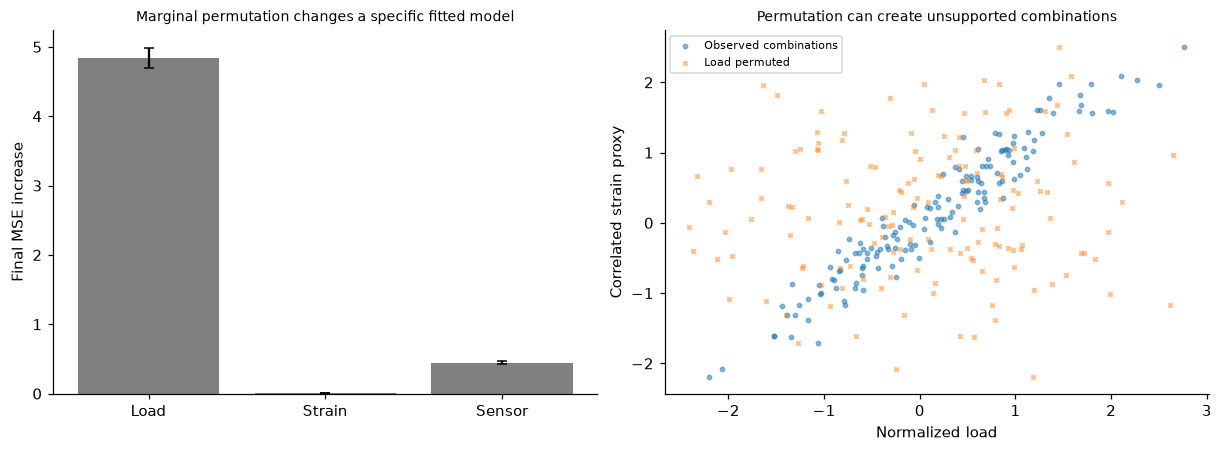

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
def cohort(n):
    load=rng.normal(size=n);strain=.97*load+np.sqrt(1-.97**2)*rng.normal(size=n);sensor=rng.normal(size=n);x=np.c_[load,strain,sensor];y=2*np.sin(load)+.7*load**2+.5*sensor+rng.normal(scale=.25,size=n);return x,y
xs,ys=cohort(1000);xf,yf=cohort(600);full=HistGradientBoostingRegressor(max_iter=120,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);reduced=HistGradientBoostingRegressor(max_iter=120,max_depth=3,early_stopping=False,random_state=SEED).fit(xs[:,[0,2]],ys);base=float(np.mean((full.predict(xf)-yf)**2));base_reduced=float(np.mean((reduced.predict(xf[:,[0,2]])-yf)**2));importance={}
for j,label in enumerate(['Load','Strain','Sensor']):
    values=[]
    for _ in range(20):z=xf.copy();z[:,j]=z[rng.permutation(600),j];values.append(float(np.mean((full.predict(z)-yf)**2)-base))
    importance[label]={'mean_MSE_increase':float(np.mean(values)),'permutation_std':float(np.std(values,ddof=1))}
reduced_imp={}
for j,label in [(0,'Load'),(1,'Sensor')]:
    vals=[]
    for _ in range(20):z=xf[:,[0,2]].copy();z[:,j]=z[rng.permutation(600),j];vals.append(float(np.mean((reduced.predict(z)-yf)**2)-base_reduced))
    reduced_imp[label]=float(np.mean(vals))
edges=np.quantile(xf[:,1],np.linspace(0,1,11));bins=np.clip(np.searchsorted(edges,xf[:,1],side='right')-1,0,9);conditional=[];joint=[]
for _ in range(20):
    z=xf.copy()
    for b in range(10):ids=np.flatnonzero(bins==b);z[ids,0]=xf[rng.permutation(ids),0]
    conditional.append(float(np.mean((full.predict(z)-yf)**2)-base));z=xf.copy();z[:,:2]=xf[rng.permutation(600),:2];joint.append(float(np.mean((full.predict(z)-yf)**2)-base))
sigma_difference=float(np.std(xs[:,0]-xs[:,1],ddof=1));permuted=xf.copy();permuted[:,0]=xf[rng.permutation(600),0];off_original=float(np.mean(abs(xf[:,0]-xf[:,1])>3*sigma_difference));off_permuted=float(np.mean(abs(permuted[:,0]-permuted[:,1])>3*sigma_difference));assert np.corrcoef(xs[:,:2],rowvar=False)[0,1]>.9;assert all(np.isfinite(r['mean_MSE_increase']) for r in importance.values());RESULTS.update(source_records=1000,final_records=600,full_final_MSE=base,reduced_final_MSE=base_reduced,marginal_permutation=importance,reduced_model_permutation=reduced_imp,within_strain_bin_load_importance=float(np.mean(conditional)),joint_load_strain_importance=float(np.mean(joint)),off_relation_original_fraction=off_original,off_relation_permuted_fraction=off_permuted,permutation_repetitions=20)
fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(np.arange(3),[importance[k]['mean_MSE_increase'] for k in importance],yerr=[importance[k]['permutation_std'] for k in importance],color='.5',capsize=3);axes[0].set(xticks=np.arange(3),xticklabels=list(importance),ylabel='Final MSE increase',title='Marginal permutation changes a specific fitted model');axes[1].scatter(xf[:150,0],xf[:150,1],s=8,alpha=.5,label='Observed combinations');axes[1].scatter(permuted[:150,0],permuted[:150,1],marker='x',s=8,alpha=.5,label='Load permuted');axes[1].set(xlabel='Normalized load',ylabel='Correlated strain proxy',title='Permutation can create unsupported combinations');axes[1].legend(fontsize=7);plt.show()


<a id="ICE-PDP-and-local-effects"></a>
 ## Compute different curves rather than rename one curve
 Use a fixed source 5–95% load grid. ICE varies load separately for each of five predeclared source rows while holding its other fields fixed; partial dependence averages the same operation over all source rows. With dependent strain this can leave the observed joint envelope. Finite-bin ALE instead averages prediction differences at the two load boundaries among rows whose observed load lies in that bin. Ten source-quantile bins define local differences, accumulated at bin midpoints using half the current-bin increment, then centered by source bin counts. This declares a midpoint approximation to first-order ALE rather than a causal intervention. Curves have arbitrary centering conventions; report those and bin counts. Differences reveal the question and support used, not a discovered effect of changing physical load while its coupled measurements stay fixed.


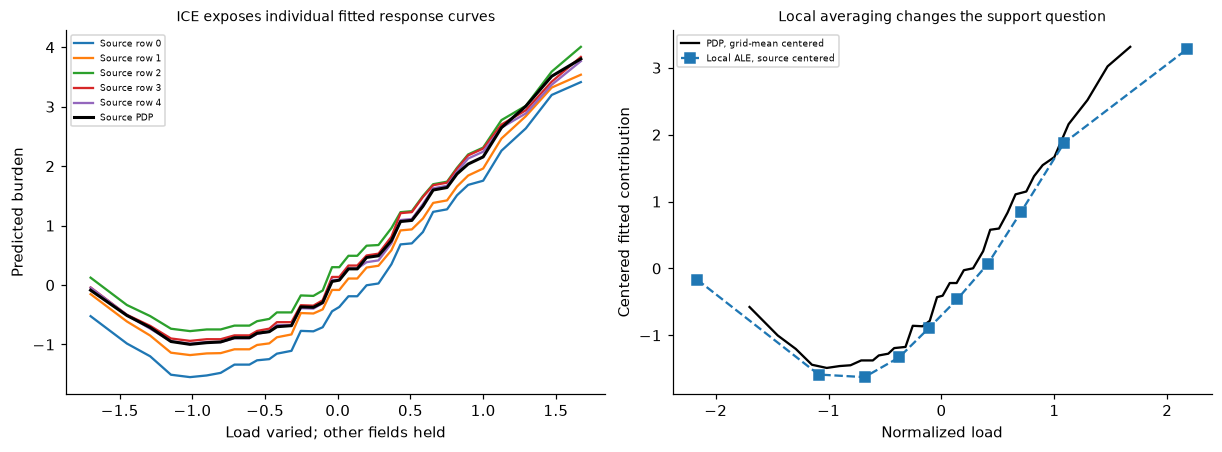

In [3]:
grid=np.quantile(xs[:,0],np.linspace(.05,.95,35));pdp=[];ice=[]
for value in grid:z=xs.copy();z[:,0]=value;pdp.append(float(full.predict(z).mean()))
for i in range(5):z=np.repeat(xs[i:i+1],len(grid),axis=0);z[:,0]=grid;ice.append(full.predict(z))
ale_edges=np.unique(np.quantile(xs[:,0],np.linspace(0,1,11)));bin_index=np.clip(np.searchsorted(ale_edges,xs[:,0],side='right')-1,0,len(ale_edges)-2);increments=[];counts=[]
for b in range(len(ale_edges)-1):
    rows=xs[bin_index==b];lo=rows.copy();hi=rows.copy();lo[:,0]=ale_edges[b];hi[:,0]=ale_edges[b+1];increments.append(float(np.mean(full.predict(hi)-full.predict(lo))));counts.append(len(rows))
increments=np.array(increments);ale=np.cumsum(increments)-.5*increments;ale-=np.average(ale,weights=counts);pdp=np.array(pdp);pdp_centred=pdp-pdp.mean();assert sum(counts)==1000 and min(counts)>0;assert np.isclose(np.average(ale,weights=counts),0,atol=1e-12);assert np.allclose(ice[0],full.predict(np.c_[grid,np.full(len(grid),xs[0,1]),np.full(len(grid),xs[0,2])]))
RESULTS.update(ALE_source_bin_counts=counts,ALE_local_increments=increments.tolist(),ALE_midpoint_centered_values=ale.tolist(),PDP_grid=grid.tolist(),PDP_values=pdp.tolist(),ALE_is_finite_bin_midpoint_approximation=True,curves_are_not_causal_interventions=True);fig,axes=plt.subplots(1,2,figsize=(11,4))
for i,curve in enumerate(ice):axes[0].plot(grid,curve,label=f'Source row {i}')
axes[0].plot(grid,pdp,color='black',linewidth=2,label='Source PDP');axes[0].set(xlabel='Load varied; other fields held',ylabel='Predicted burden',title='ICE exposes individual fitted response curves');axes[0].legend(fontsize=6);axes[1].plot(grid,pdp_centred,label='PDP, grid-mean centered',color='black');axes[1].plot((ale_edges[:-1]+ale_edges[1:])/2,ale,'s--',label='Local ALE, source centered');axes[1].set(xlabel='Normalized load',ylabel='Centered fitted contribution',title='Local averaging changes the support question');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_202','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual source fitted models with and without a correlated sensor', 'marginal joint and within-sensor-bin permutation loss changes', 'actual individual conditional expectation partial dependence and finite-bin ALE', 'support diagnostics for feature combinations and noncausal interpretation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual source fitted models with and without a correlated sensor", "marginal joint and within-sensor-bin permutation loss changes", "actual individual conditional expectation partial dependence and finite-bin ALE", "support diagnostics for feature combinations and noncausal interpretation"], "elapsed_seconds": 0.569, "example_id": "code_202", "hardware": "Darwin arm64 CPU", "results": {"ALE_is_finite_bin_midpoint_approximation": true, "ALE_local_increments": [-2.6032862213454444, -0.23679388412817204, 0.15982693372798118, 0.4294900127323021, 0.4478977312432306, 0.4104339107343914, 0.6486508172028642, 0.9012871201849848, 1.1677824892670015, 1.6439737011412858], "ALE_midpoint_centered_values": [-0.16703974398620258, -1.5870797967230108, -1.625563271923106, -1.330904798692964, -0.8922109267051979, -0.4630451057163869, 0.06649725825224095, 0.8414662269461654, 1.8760010316721585, 3.2818791268763023], "ALE_source_bin_counts": [100, 100, 100,